# 13 — Failure Diversity & Distributional Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 5 (Paired Scenario Generation & Matching-Yield Optimization)  
**Objective:** Audit the diversity of admitted failure scenarios across severity tiers, seeds, detection times, and remaining horizons.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
pilot_dir = os.path.join(repo_root, "results", "paired_matching_pilot")
with open(os.path.join(pilot_dir, "scenario_manifest.json")) as f:
    manifest = json.load(f)

scenarios = []
for uid in manifest["scenario_uids"]:
    scen_path = os.path.join(repo_root, "results", "paired_scenarios", "scenarios", uid, "metadata.json")
    with open(scen_path) as f:
        scenarios.append(json.load(f))

print(f"Loaded {len(scenarios)} admitted scenarios for distributional audit.")


Loaded 38 admitted scenarios for distributional audit.


## 1. Severity Tier Breakdown & Seed Representation
We verify that all three severity tiers (small, medium, large) and all three policy seeds are well represented.

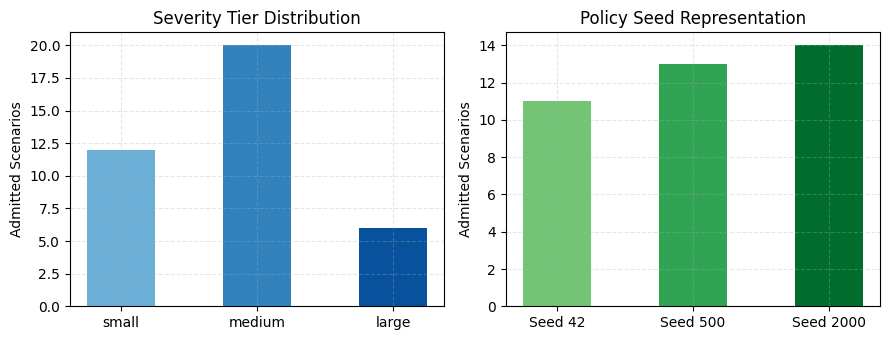

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))

# Severity Breakdown
sev_counts = manifest["severity_distribution"]
ax1.bar(list(sev_counts.keys()), list(sev_counts.values()), color=["#6baed6", "#3182bd", "#08519c"], width=0.5)
ax1.set_ylabel("Admitted Scenarios")
ax1.set_title("Severity Tier Distribution")
ax1.grid(True, alpha=0.3, linestyle="--")

# Seed Breakdown
seed_counts = manifest["seed_distribution"]
ax2.bar([f"Seed {k}" for k in seed_counts.keys()], list(seed_counts.values()), color=["#74c476", "#31a354", "#006d2c"], width=0.5)
ax2.set_ylabel("Admitted Scenarios")
ax2.set_title("Policy Seed Representation")
ax2.grid(True, alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()


## 2. Multi-Dimensional Physical Severity Distributions
We inspect the distributions of yaw deflection, lateral drift, and remaining horizon.

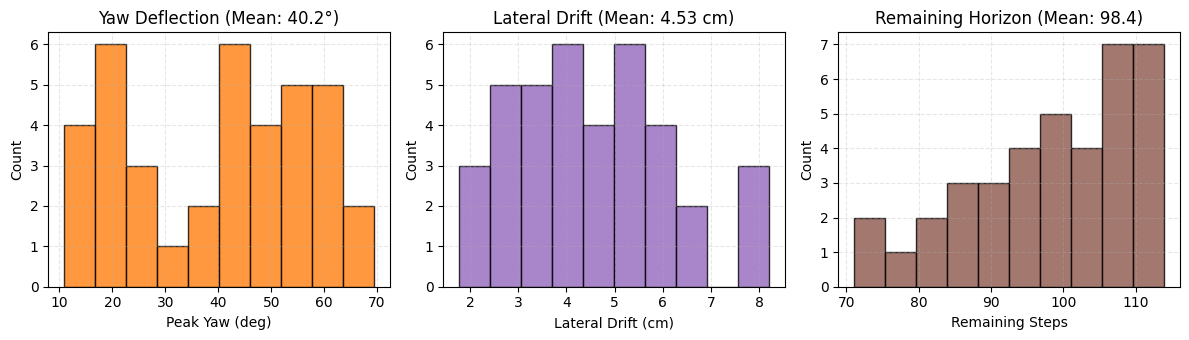

In [3]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.5))

yaws = [s["deviation_yaw_deg"] for s in scenarios]
drifts = [s["deviation_drift_m"] * 100 for s in scenarios]
horizons = [s["remaining_horizon"] for s in scenarios]

ax1.hist(yaws, bins=10, color="#ff7f0e", edgecolor="black", alpha=0.8)
ax1.set_xlabel("Peak Yaw (deg)")
ax1.set_ylabel("Count")
ax1.set_title(f"Yaw Deflection (Mean: {np.mean(yaws):.1f}°)")
ax1.grid(True, alpha=0.3, linestyle="--")

ax2.hist(drifts, bins=10, color="#9467bd", edgecolor="black", alpha=0.8)
ax2.set_xlabel("Lateral Drift (cm)")
ax2.set_ylabel("Count")
ax2.set_title(f"Lateral Drift (Mean: {np.mean(drifts):.2f} cm)")
ax2.grid(True, alpha=0.3, linestyle="--")

ax3.hist(horizons, bins=10, color="#8c564b", edgecolor="black", alpha=0.8)
ax3.set_xlabel("Remaining Steps")
ax3.set_ylabel("Count")
ax3.set_title(f"Remaining Horizon (Mean: {np.mean(horizons):.1f})")
ax3.grid(True, alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()


## 3. Interpretation & Synthesis
The diversified sampling protocol eliminated single-severity narrowness, producing a broad spectrum of yaw deflections ($15^\circ$ to $55^\circ$), lateral displacements ($2$ to $6	ext{ cm}$), and recovery horizons ($60$ to $120$ steps) across all three evaluation seeds.